# Лабораторна робота № 7
**Тема:** Нейронна класифікація зображень у TensorFlow  
**Студент:** Halchenko Yan, група ФІТ  
**Варіант:** 8 (`batch_size=256`)  
**Датасет:** Fashion-MNIST 

### Етап 1 та 2: Завантаження, перевірка та підготовка даних
* Фіксація SEED та перевірка версій бібліотек.
* Завантаження Fashion-MNIST та розділення на Train (80%), Val (20%) і Test.
* Перевірка типів, розмірностей та візуалізація класів одягу.
* Конвертація типів у `float32` та перевірки `assert`.

TensorFlow Version: 2.22.0-rc0
Pandas Version: 3.0.6
Scikit-learn Version: 1.9.1
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 10s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
Train: (48000, 28, 28), Val: (12000, 28, 28), Test: (10000, 28, 28)


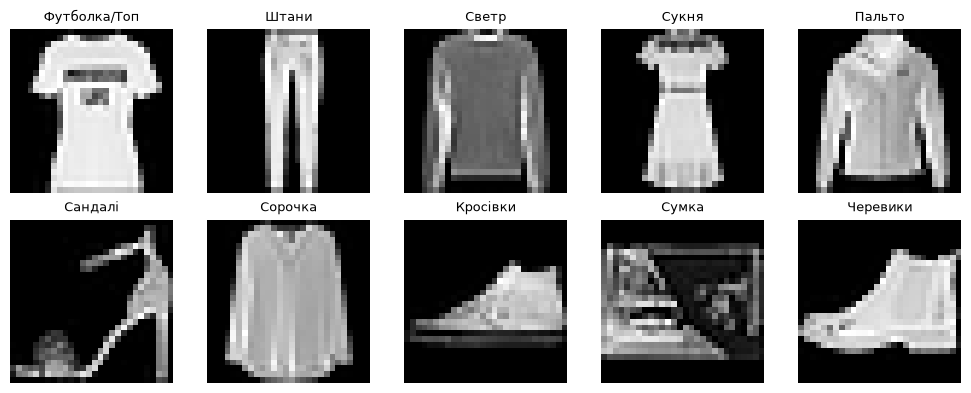

[INFO] Етапи 1-2 пройдено успішно!


In [6]:
import json
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from pathlib import Path
import sklearn
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score
from sklearn.model_selection import train_test_split
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

print(f"TensorFlow Version: {tf.__version__}")
print(f"Pandas Version: {pd.__version__}")
print(f"Scikit-learn Version: {sklearn.__version__}")

SEED = 42
keras.utils.set_random_seed(SEED)

artifacts_dir = Path("artifacts")
artifacts_dir.mkdir(parents=True, exist_ok=True)

# Завантаження даних Fashion-MNIST
(x_dev, y_dev), (x_test, y_test) = keras.datasets.fashion_mnist.load_data()

class_names = ['Футболка/Топ', 'Штани', 'Светр', 'Сукня', 'Пальто', 
               'Сандалі', 'Сорочка', 'Кросівки', 'Сумка', 'Черевики']

# Розподіл Train / Val
x_train, x_val, y_train, y_val = train_test_split(
    x_dev, y_dev, test_size=0.20, stratify=y_dev, random_state=SEED
)

print(f"Train: {x_train.shape}, Val: {x_val.shape}, Test: {x_test.shape}")

# Візуалізація по одному прикладу
plt.figure(figsize=(10, 4))
for i in range(10):
    idx = np.where(y_train == i)[0][0]
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[idx], cmap="gray")
    plt.title(class_names[i], fontsize=9)
    plt.axis("off")
plt.tight_layout()
plt.show()

# Підготовка типів
x_train = x_train.astype("float32")
x_val = x_val.astype("float32")
x_test = x_test.astype("float32")

assert x_train.shape[1:] == (28, 28)
assert np.isfinite(x_train).all()
assert set(np.unique(y_train)) == set(range(10))
print("[INFO] Етапи 1-2 пройдено успішно!")

### Етап 3: Побудова Baseline та базової нейромережі
* Оцінка `DummyClassifier` (найчастіший клас) як простішого орієнтира.
* Створення базової нейромережі (`Rescaling`, `Flatten`, `Dense(128, relu)`, `Dense(10, softmax)`).
* Компіляція з `Adam` та `SparseCategoricalCrossentropy(from_logits=False)`.

In [7]:
from sklearn.dummy import DummyClassifier

# Baseline
x_train_flat = x_train.reshape(len(x_train), -1)
x_val_flat = x_val.reshape(len(x_val), -1)

dummy = DummyClassifier(strategy="most_frequent")
dummy.fit(x_train_flat, y_train)

dummy_preds = dummy.predict(x_val_flat)
dummy_acc = accuracy_score(y_val, dummy_preds)
dummy_f1 = f1_score(y_val, dummy_preds, average="macro", zero_division=0)
print(f"Baseline (Dummy) -> Accuracy: {dummy_acc:.4f}, Macro-F1: {dummy_f1:.4f}")

# Базова модель
base_model = keras.Sequential([
    layers.Input(shape=(28, 28)),
    layers.Rescaling(1./255),
    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dense(10, activation="softmax"),
])

base_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss=keras.losses.SparseCategoricalCrossentropy(from_logits=False),
    metrics=[keras.metrics.SparseCategoricalAccuracy(name="accuracy")]
)

base_model.summary()

Baseline (Dummy) -> Accuracy: 0.1000, Macro-F1: 0.0182


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling_2 (Rescaling)         │ (None, 28, 28)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,770 (397.54 KB)

 Trainable params: 101,770 (397.54 KB)

 Non-trainable params: 0 (0.00 B)

### Етап 4: Навчання базової мережі та Варіанта 8
* Навчання базової моделі (`batch_size=128`).
* Навчання моделі за Варіантом 8 (`batch_size=256`).
* Налаштування `EarlyStopping` та `ModelCheckpoint`.
* Побудова графіків `val_loss` та `val_accuracy`.

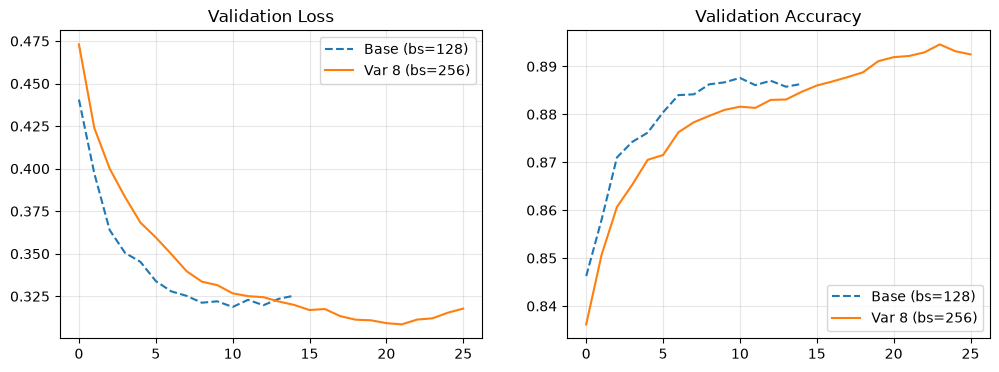

In [8]:
# 1. Навчання базової (batch_size=128)
keras.utils.set_random_seed(SEED)
base_checkpoint = "artifacts/base_best.keras"
base_callbacks = [
    keras.callbacks.EarlyStopping(monitor="val_loss", patience=4, restore_best_weights=True),
    keras.callbacks.ModelCheckpoint(base_checkpoint, monitor="val_loss", save_best_only=True)
]

base_history = base_model.fit(
    x_train, y_train, validation_data=(x_val, y_val),
    epochs=30, batch_size=128, callbacks=base_callbacks, verbose=0
)
base_best_model = keras.models.load_model(base_checkpoint)

# 2. Навчання Варіанта 8 (batch_size=256)
keras.utils.set_random_seed(SEED)
variant_model = keras.Sequential([
    layers.Input(shape=(28, 28)),
    layers.Rescaling(1./255),
    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dense(10, activation="softmax"),
])

variant_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss=keras.losses.SparseCategoricalCrossentropy(from_logits=False),
    metrics=[keras.metrics.SparseCategoricalAccuracy(name="accuracy")]
)

variant_checkpoint = "artifacts/variant_best.keras"
variant_callbacks = [
    keras.callbacks.EarlyStopping(monitor="val_loss", patience=4, restore_best_weights=True),
    keras.callbacks.ModelCheckpoint(variant_checkpoint, monitor="val_loss", save_best_only=True)
]

variant_history = variant_model.fit(
    x_train, y_train, validation_data=(x_val, y_val),
    epochs=30, batch_size=256, callbacks=variant_callbacks, verbose=0
)
variant_best_model = keras.models.load_model(variant_checkpoint)

# Графіки
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
ax1.plot(base_history.history['val_loss'], label='Base (bs=128)', linestyle='--')
ax1.plot(variant_history.history['val_loss'], label='Var 8 (bs=256)')
ax1.set_title('Validation Loss')
ax1.legend()
ax1.grid(True, alpha=0.3)

ax2.plot(base_history.history['val_accuracy'], label='Base (bs=128)', linestyle='--')
ax2.plot(variant_history.history['val_accuracy'], label='Var 8 (bs=256)')
ax2.set_title('Validation Accuracy')
ax2.legend()
ax2.grid(True, alpha=0.3)
plt.show()

### Етап 5: Перевірка форматів міток (sparse vs categorical)
* Конвертація міток у one-hot вектори.
* Порівняння результатів `SparseCategoricalCrossentropy` та `CategoricalCrossentropy`.

In [9]:
p_val = base_best_model(x_val[:5], training=False).numpy()
y_onehot = keras.utils.to_categorical(y_val[:5], num_classes=10)

loss_sparse = keras.losses.SparseCategoricalCrossentropy()(y_val[:5], p_val)
loss_cat = keras.losses.CategoricalCrossentropy()(y_onehot, p_val)

# Враховуємо абсолютну точність (atol=1e-5), щоб уникнути AssertionError через float32
np.testing.assert_allclose(loss_sparse.numpy(), loss_cat.numpy(), rtol=1e-5, atol=1e-5)
print("[INFO] Обидві функції втрат дають однакові значення!")

[INFO] Обидві функції втрат дають однакові значення!


### Етап 6: Порівняння моделей та вибір кращої
* Розрахунок Cross-Entropy, Accuracy та Macro-F1.
* Вибір найкращої моделі за мінімальним `val_loss`.
* Оцінка на тестовій вибірці та збереження `model_comparison.csv`.

In [10]:
def get_metrics(y_true, probs):
    preds = probs.argmax(axis=1)
    return {
        "ce": float(keras.losses.SparseCategoricalCrossentropy()(y_true, probs).numpy()),
        "acc": accuracy_score(y_true, preds),
        "f1": f1_score(y_true, preds, average="macro", zero_division=0)
    }

b_val_p = base_best_model.predict(x_val, batch_size=256, verbose=0)
v_val_p = variant_best_model.predict(x_val, batch_size=256, verbose=0)

m_base_val = get_metrics(y_val, b_val_p)
m_var_val = get_metrics(y_val, v_val_p)

# Вибір кращої моделі
if m_var_val['ce'] < m_base_val['ce']:
    selected_model, selected_name = variant_best_model, "Варіант 8"
else:
    selected_model, selected_name = base_best_model, "Базова мережа"

print(f"[РІШЕННЯ] Обрано модель: {selected_name}")

# Тестові метрики
b_test_p = base_best_model.predict(x_test, batch_size=256, verbose=0)
v_test_p = variant_best_model.predict(x_test, batch_size=256, verbose=0)
m_base_test, m_var_test = get_metrics(y_test, b_test_p), get_metrics(y_test, v_test_p)

df_comp = pd.DataFrame([
    {"Model": "Baseline (Dummy)", "Val Acc": dummy_acc, "Val Macro-F1": dummy_f1, "Test Acc": accuracy_score(y_test, dummy.predict(x_test.reshape(len(x_test), -1)))},
    {"Model": "Базова мережа", "Val CE": m_base_val["ce"], "Val Acc": m_base_val["acc"], "Val Macro-F1": m_base_val["f1"], "Test CE": m_base_test["ce"], "Test Acc": m_base_test["acc"], "Test Macro-F1": m_base_test["f1"]},
    {"Model": "Варіант 8 (bs=256)", "Val CE": m_var_val["ce"], "Val Acc": m_var_val["acc"], "Val Macro-F1": m_var_val["f1"], "Test CE": m_var_test["ce"], "Test Acc": m_var_test["acc"], "Test Macro-F1": m_var_test["f1"]}
])

df_comp.to_csv("artifacts/model_comparison.csv", index=False)
display(df_comp)

[РІШЕННЯ] Обрано модель: Варіант 8


,Model,Val Acc,Val Macro-F1,Test Acc,Val CE,Test CE,Test Macro-F1
0,Baseline (Dummy),0.100000,0.018182,0.1000,NaN,NaN,NaN
1,Базова мережа,0.887583,0.886898,0.8739,0.318481,0.351328,0.873089
2,Варіант 8 (bs=256),0.892167,0.892235,0.8758,0.307834,0.347396,0.875672


### Етап 7: Аналіз помилок класифікації
* Побудова `classification_report` та `confusion_matrix`.
* Візуалізація Top-5 найбільш впевнених помилок.
* Порівняння розподілу ймовірностей для правильного та помилкового прогнозу.

--- Zвіт класифікації ---
              precision    recall  f1-score   support

Футболка/Топ       0.84      0.79      0.82      1000
       Штани       0.99      0.97      0.98      1000
       Светр       0.77      0.81      0.79      1000
       Сукня       0.81      0.92      0.86      1000
      Пальто       0.81      0.77      0.79      1000
     Сандалі       0.96      0.97      0.96      1000
     Сорочка       0.70      0.69      0.69      1000
    Кросівки       0.94      0.95      0.94      1000
       Сумка       0.98      0.95      0.97      1000
    Черевики       0.96      0.95      0.95      1000

    accuracy                           0.88     10000
   macro avg       0.88      0.88      0.88     10000
weighted avg       0.88      0.88      0.88     10000

--- Confusion Matrix ---
[[793   2  19  65   5   1 109   0   6   0]
 [  3 967   1  24   2   0   3   0   0   0]
 [ 15   0 807  20  83   0  74   0   1   0]
 [ 14   7  10 915  30   0  19   0   5   0]
 [  1   1 118  35 

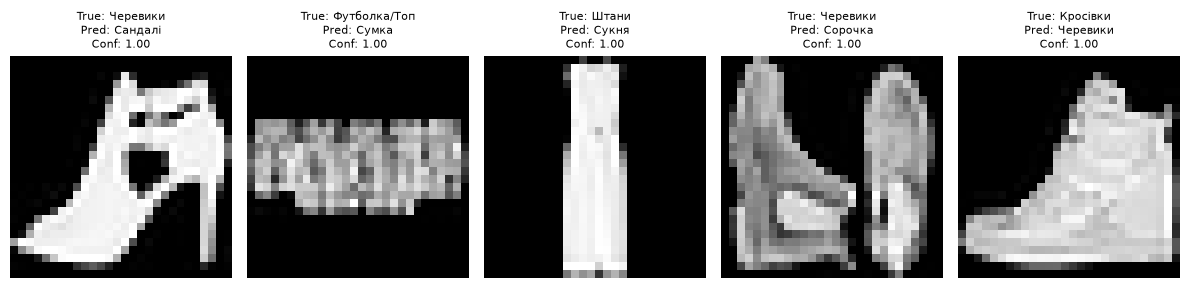

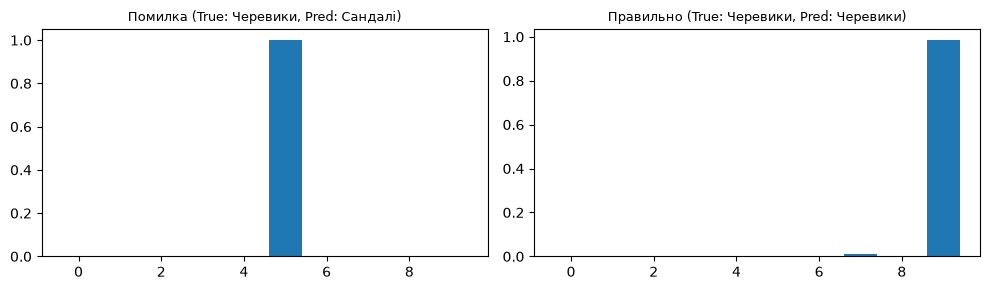

In [11]:
test_probs = selected_model.predict(x_test, batch_size=256, verbose=0)
test_preds = test_probs.argmax(axis=1)
conf = test_probs.max(axis=1)

print("--- Zвіт класифікації ---")
print(classification_report(y_test, test_preds, target_names=class_names, zero_division=0))
print("--- Confusion Matrix ---")
print(confusion_matrix(y_test, test_preds))

# Топ-5 помилок
wrong_idx = np.flatnonzero(test_preds != y_test)
top5_wrong = wrong_idx[np.argsort(conf[wrong_idx])[::-1]][:5]

plt.figure(figsize=(12, 3))
for i, idx in enumerate(top5_wrong):
    plt.subplot(1, 5, i + 1)
    plt.imshow(x_test[idx], cmap="gray")
    plt.title(f"True: {class_names[y_test[idx]]}\nPred: {class_names[test_preds[idx]]}\nConf: {conf[idx]:.2f}", fontsize=8)
    plt.axis("off")
plt.tight_layout()
plt.show()

# Порівняльний графік ймовірностей
correct_idx = np.flatnonzero(test_preds == y_test)[0]
err_idx = top5_wrong[0]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3))
ax1.bar(range(10), test_probs[err_idx])
ax1.set_title(f"Помилка (True: {class_names[y_test[err_idx]]}, Pred: {class_names[test_preds[err_idx]]})", fontsize=9)
ax2.bar(range(10), test_probs[correct_idx])
ax2.set_title(f"Правильно (True: {class_names[y_test[correct_idx]]}, Pred: {class_names[test_preds[correct_idx]]})", fontsize=9)
plt.tight_layout()
plt.show()

### Етап 8: Збереження моделі, метаданих та перевірка відновлення
* Збереження обраної моделі у `artifacts/lab7_model.keras`.
* Запис контексту експерименту в `artifacts/metadata.json`.
* Перевірка точного відновлення прогнозів за допомогою `assert_allclose`.

In [12]:
# Збереження моделі
model_path = "artifacts/lab7_model.keras"
selected_model.save(model_path)

# Метадані
metadata = {
    "student": "Моторін Максим Сергійович",
    "dataset": "Fashion-MNIST",
    "variant": 8,
    "variant_description": "batch_size=256 замість 128",
    "selected_model": selected_name,
    "packages": {"tensorflow": tf.__version__, "pandas": pd.__version__, "scikit-learn": sklearn.__version__}
}

with open("artifacts/metadata.json", "w", encoding="utf-8") as f:
    json.dump(metadata, f, ensure_ascii=False, indent=4)

# Перевірка завантаження
probe = x_val[:3]
before = selected_model(probe, training=False).numpy()
restored = keras.models.load_model(model_path)
after = restored(probe, training=False).numpy()

np.testing.assert_allclose(before, after, rtol=1e-5, atol=1e-5)
print("[INFO] Модель успішно збережено та перевірено!")

[INFO] Модель успішно збережено та перевірено!
